# Chapitre 8 - Cours 2 : Augmentation et synthèse de données

Annoter coûte cher, et certaines données sont rares, dangereuses ou privées. Depuis
longtemps, l'industrie rêve de **produire des données par programme**. Ce notebook suit
la section *Data Augmentation and Synthesis* du livre :

1. augmentation ou synthèse, et **pourquoi** synthétiser (section *Why Data Synthesis*) ;
2. les techniques **à base de règles** : gabarits (section *Rule-based data synthesis*) ;
3. les **transformations et perturbations** : substitution, contrefactuels de genre,
   fautes de frappe, avec une expérience de robustesse ;
4. la **simulation** (section *Simulation*) ;
5. la **synthèse d'instructions par IA** avec Qwen2.5 (sections *AI-Powered Data
   Synthesis* et *Instruction data synthesis*) ;
6. la **vérification** des données synthétiques (section *Data verification*) ;
7. les **limites**, dont l'**effondrement de modèle** illustré par simulation (section
   *Limitations to AI-generated data*) ;
8. la **distillation** de modèles (section *Model Distillation*).

Modèles utilisés : Qwen2.5-1.5B-Instruct comme **générateur** (la qualité du français
l'exige : le 0,5B produit trop souvent des phrases incohérentes pour servir de source) et
Qwen2.5-0.5B-Instruct comme **solveur** dont on vérifie les réponses. Les deux ne sont
jamais chargés en même temps, pour ménager la mémoire du GPU.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import ch08_donnees as d8
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.max_colwidth", 110)
rng = np.random.default_rng(0)
GEN = llm.MEDIUM   # générateur de données synthétiques
SOLV = llm.SMALL   # petit modèle dont on vérifie les sorties


def titre(ax, texte, sous_titre):
    """Titre d'axe suivi d'un sous-titre gris."""
    ax.set_title(texte, pad=18)
    subtitle(ax, sous_titre)

def log_lisible(ax, axes="y"):
    """Graduations log au format décimal simple (la police du socle n'a pas le signe moins
    typographique utilisé par les exposants mathtext)."""
    from matplotlib.ticker import FuncFormatter, NullFormatter
    for a in axes:
        axis = ax.yaxis if a == "y" else ax.xaxis
        axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(NullFormatter())


def court(t, n=110):
    """Tronque un texte pour l'affichage."""
    t = " ".join(t.split())
    return t if len(t) <= n else t[:n - 3] + "..."

## 1. Augmenter ou synthétiser ? (section *Why Data Synthesis*)

Le livre distingue deux processus :

- l'**augmentation** crée de nouvelles données **à partir de données réelles** (retourner
  la photo d'un chat donne une autre photo du même chat) ;
- la **synthèse** génère des données qui **imitent** les propriétés des données réelles
  (simuler les mouvements de souris d'un robot sur une page web).

Le but commun étant d'automatiser la création de données, le livre emploie souvent
« synthèse » pour les deux. Il recense cinq motivations : améliorer le trio
**quantité, couverture, qualité**, protéger la **vie privée**, et **distiller** des
modèles.

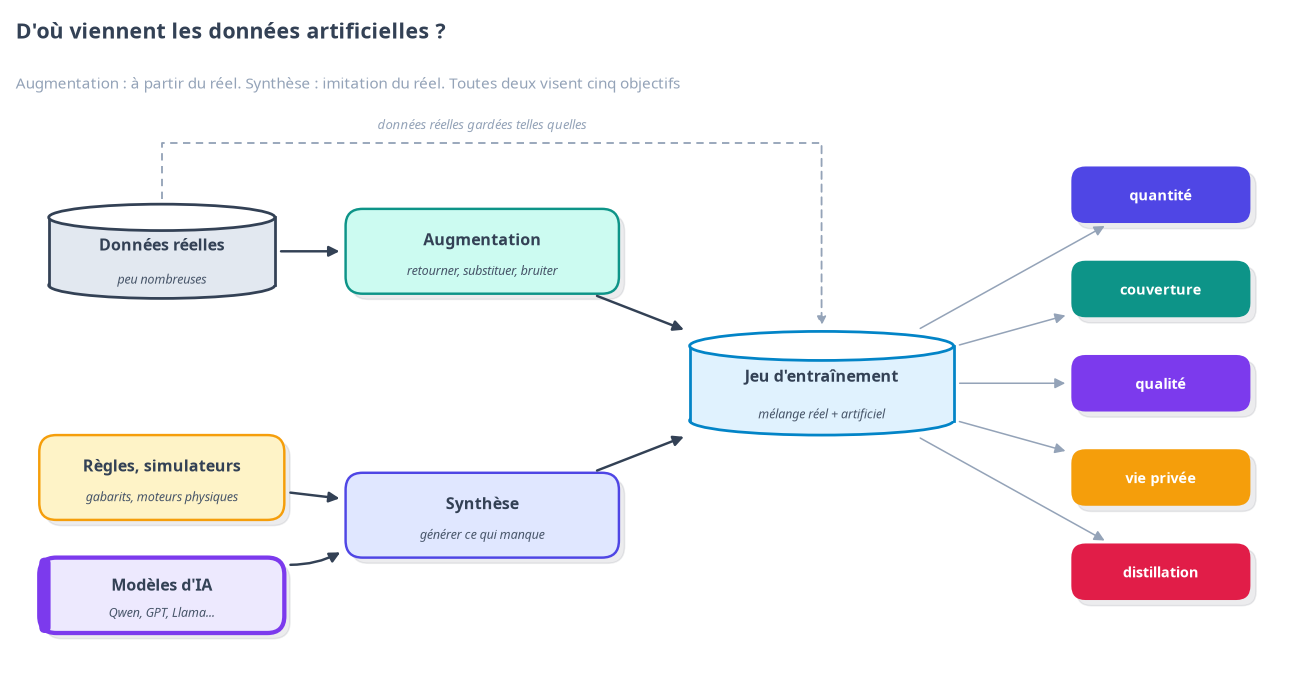

In [2]:
d = Diagram(13.5, 6.0, title="D'où viennent les données artificielles ?",
            subtitle="Augmentation : à partir du réel. Synthèse : imitation du réel. Toutes deux visent cinq objectifs")
d.box("reel", 1.6, 4.4, "Données réelles", sub="peu nombreuses", color=SLATE, kind="db", w=2.4, h=1.0)
d.box("aug", 5.0, 4.4, "Augmentation", sub="retourner, substituer, bruiter", color=TEAL, w=2.9)
d.box("regles", 1.6, 2.0, "Règles, simulateurs", sub="gabarits, moteurs physiques", color=AMBER, w=2.6)
d.box("ia", 1.6, 0.75, "Modèles d'IA", sub="Qwen, GPT, Llama...", color=VIOLET, kind="model", w=2.6, h=0.8)
d.box("syn", 5.0, 1.6, "Synthèse", sub="générer ce qui manque", color=INDIGO, w=2.9)
d.box("jeu", 8.6, 3.0, "Jeu d'entraînement", sub="mélange réel + artificiel", color=SKY, kind="db", w=2.8, h=1.1)
d.arrow("reel", "aug")
d.arrow("regles", "syn")
d.arrow("ia", "syn", rad=0.15)
d.arrow("aug", "jeu")
d.arrow("syn", "jeu")
d.line([(1.6, 4.95), (1.6, 5.55), (8.6, 5.55), (8.6, 3.58)], color=GRAY, style="dashed")
d.note(5.0, 5.75, "données réelles gardées telles quelles", color=GRAY, fontsize=8.5)
for i, (t, c) in enumerate([("quantité", INDIGO), ("couverture", TEAL), ("qualité", VIOLET),
                            ("vie privée", AMBER), ("distillation", ROSE)]):
    y = 5.0 - i * 1.0
    d.box(f"o{i}", 12.2, y, t, color=c, kind="tag", w=1.9, h=0.6, fontsize=9.5)
    d.arrow("jeu", f"o{i}", color=GRAY, lw=1.0)
d.show()

Quelques exemples du livre pour chaque objectif :

| Objectif | Idée | Exemple |
|---|---|---|
| Quantité | produire à l'échelle là où le réel est rare | accidents pour la conduite autonome |
| Couverture | cibler des comportements ou classes rares | résumés volontairement incohérents pour entraîner un détecteur (TrueTeacher) |
| Qualité | dépasser les limites humaines | données d'usage d'outils, problèmes de maths difficiles, préférences plus cohérentes |
| Vie privée | remplacer des données sensibles | dossiers médicaux ou sinistres d'assurance synthétiques |
| Distillation | imiter un modèle plus gros | entraîner un petit modèle sur les sorties d'un grand |

> **À retenir.** L'augmentation transforme des données réelles, la synthèse imite le
> réel. On y recourt pour la quantité, la couverture, la qualité, la vie privée et la
> distillation, mais les données artificielles **complètent** les données humaines plus
> qu'elles ne les remplacent.

## 2. Règles et gabarits (section *Rule-based data synthesis*)

La méthode la plus simple : un **gabarit** dont on remplit les champs par tirage
aléatoire (comme le fait la bibliothèque Faker). C'est la **génération procédurale** des
jeux vidéo, appliquée aux données. Le livre prend l'exemple de transactions bancaires :
trop sensibles pour être partagées, elles sont d'abord synthétisées pour prouver la
faisabilité d'un détecteur de fraude. Faisons-le, en injectant volontairement 3 % de
fraudes (une classe rare que l'on veut **couvrir**).

In [3]:
marchands = {"alimentation": ["Carrefour Market", "Biocoop", "Boulangerie Paul"],
             "transport": ["SNCF Connect", "Uber", "TotalEnergies"],
             "loisirs": ["Fnac", "Cinéma Pathé", "Decathlon"],
             "en ligne": ["Amazon", "Vinted", "Steam"]}
villes = ["Lyon, France", "Paris, France", "Lille, France", "Nantes, France"]


def transaction(i, rng, fraude=False):
    cat = list(marchands)[rng.integers(4)]
    montant = rng.lognormal(3.2, 0.8) if not fraude else rng.uniform(900, 4000)
    heure = int(rng.integers(7, 23)) if not fraude else int(rng.integers(1, 5))
    return {"id": f"TX{i:05d}", "date": f"2026-{rng.integers(1, 13):02d}-{rng.integers(1, 29):02d}",
            "heure": f"{heure:02d}:{rng.integers(60):02d}", "montant (euros)": round(float(montant), 2),
            "marchand": marchands[cat][rng.integers(3)], "catégorie": cat,
            "lieu": villes[rng.integers(4)] if not fraude else "Lagos, Nigeria",
            "statut": rng.choice(["validée", "validée", "validée", "en attente", "refusée"]),
            "fraude": int(fraude)}


tx = pd.DataFrame([transaction(i, rng, fraude=rng.random() < 0.03) for i in range(2000)])
tx.head(6)

,id,date,heure,montant (euros),marchand,catégorie,lieu,statut,fraude
0,TX00000,2026-01-01,11:10,40.95,Decathlon,loisirs,"Lille, France",refusée,0
1,TX00001,2026-07-27,18:16,13.97,Steam,en ligne,"Lille, France",validée,0
2,TX00002,2026-11-05,07:05,9.05,Decathlon,loisirs,"Lyon, France",validée,0
3,TX00003,2026-01-04,13:00,22.14,TotalEnergies,transport,"Lille, France",en attente,0
4,TX00004,2026-10-28,13:22,13.53,Steam,en ligne,"Nantes, France",en attente,0
5,TX00005,2026-07-21,13:50,21.60,Cinéma Pathé,loisirs,"Paris, France",validée,0


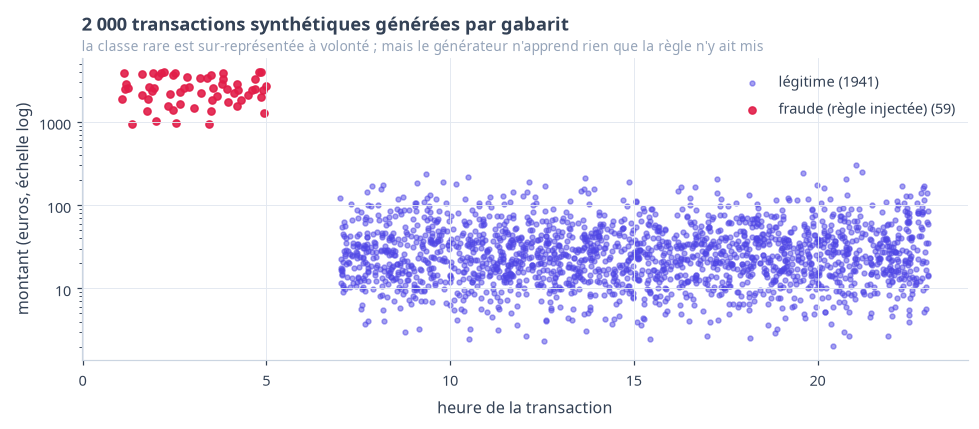

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for f, c, lab in [(0, INDIGO, "légitime"), (1, ROSE, "fraude (règle injectée)")]:
    sub = tx[tx.fraude == f]
    ax.scatter(sub["heure"].str[:2].astype(int) + rng.random(len(sub)), sub["montant (euros)"],
               s=10 if f == 0 else 22, alpha=0.5 if f == 0 else 0.9, color=c, label=f"{lab} ({len(sub)})")
ax.set_yscale("log")
log_lisible(ax)
ax.set_xlabel("heure de la transaction")
ax.set_ylabel("montant (euros, échelle log)")
titre(ax, "2 000 transactions synthétiques générées par gabarit",
      "la classe rare est sur-représentée à volonté ; mais le générateur n'apprend rien que la règle n'y ait mis")
ax.legend(loc="upper right")
finish(fig)
plt.show()

Le revers de la médaille est visible : la fraude est **parfaitement séparable** parce que
nous l'avons définie par une règle simple. Un détecteur entraîné sur ces données
apprendra notre règle, pas la fraude réelle. Les gabarits servent donc à **démarrer**
(prouver la faisabilité, tester un pipeline), avant l'accès aux vraies données.

Les gabarits brillent quand la donnée suit une **grammaire** : documents structurés
(factures, CV), expressions régulières, **équations et problèmes de maths**. Le livre
cite AlphaGeometry, entraîné sur 100 millions d'exemples synthétiques. Nous générons
ainsi des problèmes arithmétiques dont **la réponse est connue par construction**, ce
qui servira à la vérification (section 6).

In [5]:
problemes = d8.make_word_problems(6, seed=1)
pd.DataFrame(problemes)[["question", "answer"]]

,question,answer
0,"Un train transporte 57 passagers. À la gare, 9 descendent et 9 montent. Combien de passagers y a-t-il dans...",57
1,"Une boulangerie a 57 croissants. Elle en vend 4, puis en cuit 10 de plus. Combien de croissants a-t-elle m...",63
2,Léa possède 29 billes. Elle en donne 6 à son frère et en gagne 10 à la récréation. Combien de billes a-t-e...,33
3,Léa possède 32 billes. Elle en donne 12 à son frère et en gagne 4 à la récréation. Combien de billes a-t-e...,24
4,Un magasin reçoit 2 cartons de 9 bouteilles et en avait déjà 11. Combien de bouteilles a-t-il au total ?,29
5,Une salle compte 10 rangées de 12 chaises. On retire 38 chaises abîmées. Combien reste-t-il de chaises ?,82


**Combien de gabarits ?** Le livre met en garde : produire trop d'exemples par gabarit
appauvrit la diversité. Mesurons-le avec distinct-2 (cours 1) : on génère 200
instructions en répartissant l'effort sur 1, 2, 5 ou 10 gabarits.

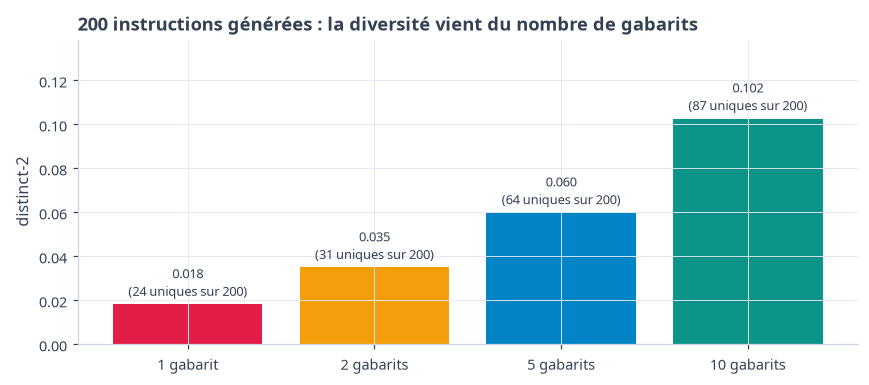

In [6]:
gabarits = ["Donne-moi une recette de {x} pour {n} personnes.", "Comment conserver des {x} plus longtemps ?",
            "Quel vin servir avec des {x} ?", "Explique à un enfant d'où viennent les {x}.",
            "Combien de calories contiennent {n} portions de {x} ?", "Propose une variante végétarienne des {x}.",
            "Quelles erreurs éviter quand on prépare des {x} ?", "Écris un poème court sur les {x}.",
            "Résume l'histoire des {x} en trois phrases.", "Compare les {x} maison et industriels."]
champs = {"x": ["crêpes", "lasagnes", "quiches", "soupes", "tartes", "gratins", "risottos", "gaufres"],
          "n": ["deux", "quatre", "six"]}
res = []
for k in [1, 2, 5, 10]:
    txt = [d8.fill_template(gabarits[i % k], champs, rng) for i in range(200)]
    res.append((k, d8.distinct_n(txt, 2), len(set(txt))))
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar([f"{k} gabarit{'s' if k > 1 else ''}" for k, *_ in res], [r[1] for r in res],
              color=[ROSE, AMBER, SKY, TEAL])
ax.bar_label(bars, labels=[f"{r[1]:.3f}\n({r[2]} uniques sur 200)" for r in res], fontsize=8.5, padding=3)
ax.set_ylabel("distinct-2")
ax.set_ylim(0, max(r[1] for r in res) * 1.35)
ax.set_title("200 instructions générées : la diversité vient du nombre de gabarits")
finish(fig)
plt.show()

Avec un seul gabarit, il n'existe que $8 \times 3 = 24$ instructions possibles : 200
tirages produisent forcément des doublons. La diversité d'un jeu à gabarits est
**bornée par la combinatoire** des gabarits et des champs.

> **À retenir.** Les gabarits produisent des données structurées et **vérifiables** à
> très bas coût, idéales pour démarrer ou pour des domaines à grammaire (maths, code,
> documents). Mais ils ne contiennent que ce que la règle y a mis, et leur diversité est
> bornée par la combinatoire : multipliez les gabarits plutôt que les tirages.

## 3. Transformations et perturbations (section *Rule-based data synthesis*)

### Substitution et contrefactuels

On peut créer un exemple en remplaçant un mot par un synonyme (« une infirmière
formidable » donne « une infirmière remarquable »), trouvé dans un dictionnaire ou par
proximité d'embeddings. Appliquée aux mots genrés, la substitution produit des
**contrefactuels** qui atténuent un biais : si « nurse » n'apparaît qu'avec « she », on
ajoute les versions avec « he ». Notre fonction `gender_swap` le fait en anglais (le
tableau 8-2 du livre en donne des exemples).

In [7]:
phrases = ["She is a wonderful nurse and her patients love her.",
           "Mr. Lee told his son that the engineer had fixed the bridge.",
           "My mom cooked dinner while my dad read a book.",
           "The waitress thanked the gentleman for his tip."]
pd.DataFrame({"original": phrases, "contrefactuel": [d8.gender_swap(p) for p in phrases]})

,original,contrefactuel
0,She is a wonderful nurse and her patients love her.,He is a wonderful nurse and his patients love his.
1,Mr. Lee told his son that the engineer had fixed the bridge.,Ms. Lee told her daughter that the engineer had fixed the bridge.
2,My mom cooked dinner while my dad read a book.,My dad cooked dinner while my mom read a book.
3,The waitress thanked the gentleman for his tip.,The waiter thanked the lady for her tip.


Regardez la première ligne : « love her » devient « love his », une faute. En anglais,
« her » correspond tantôt à « his » (possessif), tantôt à « him » (complément) : un
dictionnaire ne peut pas trancher sans analyse grammaticale. En français, c'est pire
(accords : « une infirmière dévouée » doit devenir « un infirmier dévoué »).
L'exercice 8.6 explore ces pièges ; le livre suggère de confier ces réécritures à un
modèle de langage.

### Perturbations : bruit et robustesse

La **perturbation** ajoute du bruit à des données existantes. Découverte comme une
**attaque** (changer un seul pixel suffit à tromper un classifieur d'images sur une part
importante des images de CIFAR-10, selon les travaux cités par le livre), elle sert aussi
de **défense** : entraîner sur des données perturbées rend le modèle plus robuste. BERT
remplace ainsi 1,5 % des tokens par des mots aléatoires. Pour le texte d'utilisateurs,
la perturbation la plus réaliste est la **faute de frappe**.

In [8]:
q = "Comment réinitialiser mon mot de passe ?"
pd.DataFrame({"taux de fautes": [0.0, 0.05, 0.1, 0.2, 0.3],
              "texte perturbé": [d8.typo_noise(q, r, seed=7) for r in [0.0, 0.05, 0.1, 0.2, 0.3]]})

,taux de fautes,texte perturbé
0,0.00,Comment réinitialiser mon mot de passe ?
1,0.05,Commen réinitialiser moh mot de passe ?
2,0.10,Commen réinitialiser moh mot de passe ?
3,0.20,Commen réinitialiser poo nmot de paaxse ?
4,0.30,Comemn réiniitialise pn mot de apsse ?


**Expérience.** Un classifieur d'intentions de service client (quatre intentions :
mot de passe, livraison, remboursement, horaires) est entraîné sur 400 requêtes propres
générées par gabarits, avec des sacs de mots TF-IDF et une régression logistique. On le
teste sur des requêtes de plus en plus fautives, puis on recommence en **augmentant**
l'entraînement avec une copie bruitée (8 % de fautes) de chaque requête.

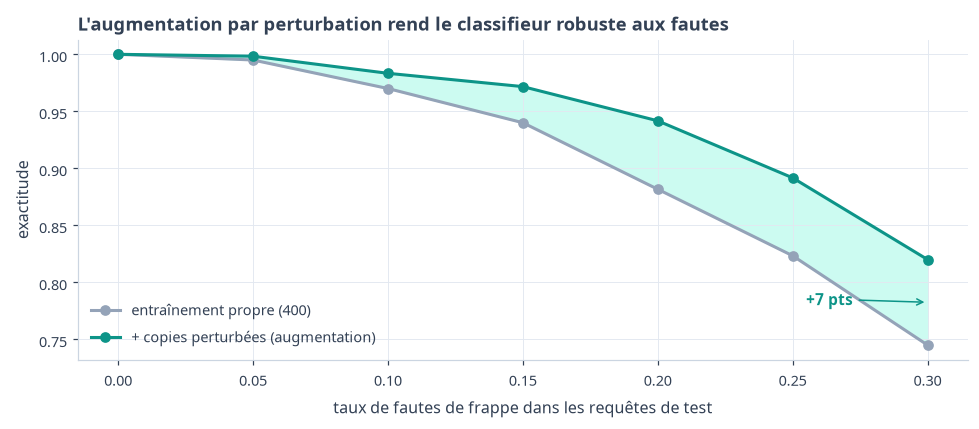

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

INTENTS = {
    "mot de passe": ["Comment {verbe} mon mot de passe ?", "J'ai {perdu} mon mot de passe {fin}",
                     "Je n'arrive plus à me connecter à mon compte {fin}", "Mot de passe {perdu}, que faire ?",
                     "Où puis-je {verbe} mon mot de passe ?"],
    "livraison": ["Où en est ma commande {fin}", "Mon colis n'est toujours pas arrivé {fin}",
                  "Quand vais-je recevoir ma livraison ?", "Comment suivre mon colis ?",
                  "Le livreur n'est pas passé {fin}"],
    "remboursement": ["Je voudrais être remboursé {fin}", "Comment obtenir un remboursement ?",
                      "Puis-je retourner un article et récupérer mon argent ?",
                      "Le produit est défectueux, je veux un remboursement {fin}", "Quel est le délai de remboursement ?"],
    "horaires": ["Quels sont vos horaires d'ouverture ?", "Le magasin est-il ouvert {jour} ?",
                 "À quelle heure fermez-vous {jour} ?", "Êtes-vous ouverts {jour} matin ?",
                 "Jusqu'à quelle heure puis-je venir {jour} ?"],
}
CHAMPS = {"verbe": ["changer", "réinitialiser", "modifier", "récupérer"], "perdu": ["oublié", "perdu", "égaré"],
          "fin": ["", ".", "!", "depuis hier", "s'il vous plaît", "merci"],
          "jour": ["dimanche", "lundi", "samedi", "le jour férié", "ce soir"]}
NOMS = list(INTENTS)


def requetes(n, seed):
    r = np.random.default_rng(seed)
    X, Y = [], []
    for _ in range(n):
        k = int(r.integers(4))
        X.append(d8.fill_template(INTENTS[NOMS[k]][r.integers(5)], CHAMPS, r).replace(" .", ".").replace(" !", "!"))
        Y.append(k)
    return X, np.array(Y)


Xtr, ytr = requetes(400, 0)
Xte, yte = requetes(600, 1)
taux = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
courbes = {}
for aug in (False, True):
    Xa = Xtr + [d8.typo_noise(x, 0.08, seed=i) for i, x in enumerate(Xtr)] if aug else Xtr
    ya = np.concatenate([ytr, ytr]) if aug else ytr
    clf = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000)).fit(Xa, ya)
    courbes[aug] = [clf.score([d8.typo_noise(x, r, seed=1000 + i) for i, x in enumerate(Xte)], yte) for r in taux]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(taux, courbes[False], "o-", color=GRAY, label="entraînement propre (400)")
ax.plot(taux, courbes[True], "o-", color=TEAL, label="+ copies perturbées (augmentation)")
ax.fill_between(taux, courbes[False], courbes[True], color=LIGHT[TEAL])
ax.annotate(f"+{(courbes[True][-1] - courbes[False][-1]) * 100:.0f} pts", xy=(0.3, (courbes[True][-1] + courbes[False][-1]) / 2),
            xytext=(0.255, 0.78), fontsize=10, color=TEAL, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=TEAL))
ax.set_xlabel("taux de fautes de frappe dans les requêtes de test")
ax.set_ylabel("exactitude")
ax.set_title("L'augmentation par perturbation rend le classifieur robuste aux fautes")
ax.legend(loc="lower left")
finish(fig)
plt.show()

Sans augmentation, chaque faute crée un mot **inconnu** du vocabulaire TF-IDF et
l'exactitude chute quand les fautes se multiplient. Les copies perturbées apprennent au
modèle que les variantes fautives existent : la chute est nettement amortie. C'est le
principe des jeux de test comme ImageNet-C (15 corruptions visuelles) cités par le livre,
appliqué ici au texte. (Une représentation par $n$-grammes de **caractères** serait,
elle, robuste par construction : l'augmentation et le choix de représentation sont deux
leviers complémentaires.)

> **À retenir.** Substitutions, contrefactuels et perturbations créent des variantes
> d'exemples réels à coût quasi nul. Elles améliorent la robustesse et atténuent des
> biais, à condition que la transformation **préserve l'étiquette** (une faute de frappe
> ne change pas l'intention ; un mauvais accord de genre, si).

## 4. Simulation (section *Simulation*)

Au lieu de collecter des données dans le monde réel, coûteux ou dangereux, on les
**simule** : un cheval sur l'autoroute pour une voiture autonome (simulateurs comme
CARLA), des défauts de fabrication, des scénarios financiers extrêmes. Le livre décrit
le cas d'un robot qui doit verser du café : on ne sait pas comment bouger chaque
articulation, alors on **simule** de nombreux mouvements et l'on **ne garde que ceux qui
réussissent** comme données d'entraînement.

Simulons-le avec deux paramètres : l'angle d'inclinaison de la tasse et la vitesse du
geste. Le « simulateur » (une règle physique simplifiée et bruitée) dit si le café est
versé sans débordement.

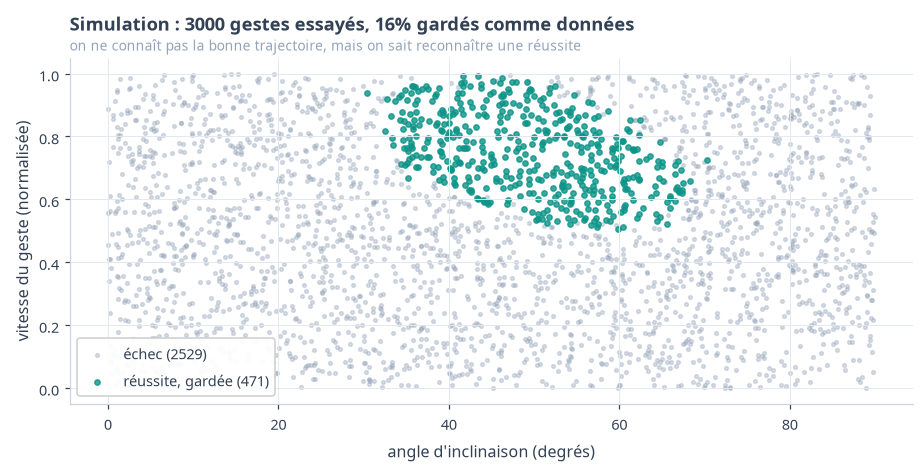

In [10]:
n_essais = 3000
angle = rng.uniform(0, 90, n_essais)
vitesse = rng.uniform(0, 1, n_essais)
# zone de réussite : un angle suffisant pour verser, une vitesse d'autant plus faible que l'angle est grand
marge = 1 - ((angle - 50) / 18) ** 2 - ((vitesse - 0.75 + 0.006 * (angle - 50)) / 0.22) ** 2
reussi = marge + rng.normal(0, 0.15, n_essais) > 0

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.scatter(angle[~reussi], vitesse[~reussi], s=6, color=GRAY, alpha=0.35, label=f"échec ({(~reussi).sum()})")
ax.scatter(angle[reussi], vitesse[reussi], s=12, color=TEAL, alpha=0.8, label=f"réussite, gardée ({reussi.sum()})")
ax.set_xlabel("angle d'inclinaison (degrés)")
ax.set_ylabel("vitesse du geste (normalisée)")
titre(ax, f"Simulation : {n_essais} gestes essayés, {reussi.mean():.0%} gardés comme données",
      "on ne connaît pas la bonne trajectoire, mais on sait reconnaître une réussite")
ax.legend(loc="lower left", frameon=True, facecolor="white", framealpha=0.95)
finish(fig)
plt.show()

Ce schéma « **générer beaucoup, vérifier, filtrer** » est le cœur de toute la synthèse
moderne : on le retrouvera avec les LLM. Il s'applique aussi à l'**usage d'outils** :
pour une requête, on simule plusieurs séquences d'actions, on les exécute et l'on garde
la plus efficace comme réponse annotée. Le livre rappelle la limite : un robot qui
réussit en simulation peut échouer dans le monde réel (le domaine **Sim2Real** étudie ce
transfert), mais un robot qui échoue en simulation échouera sûrement dans le réel.

**Les événements rares.** Si un défaut de fabrication touche une pièce sur 1 000, il
faut inspecter en moyenne 100 000 pièces pour observer 100 défauts. Un simulateur peut
produire un jeu équilibré (50 % de défauts) en quelques minutes : c'est souvent la seule
façon de couvrir la classe rare.

> **À retenir.** La simulation remplace des expériences coûteuses ou dangereuses et
> fabrique des événements rares à volonté. Son principe, générer puis ne garder que ce
> qui réussit, est le même que celui de la synthèse par IA vérifiée.

## 5. Synthèse d'instructions par IA (sections *AI-Powered Data Synthesis* et *Instruction data synthesis*)

Les modèles de fondation ouvrent un champ nouveau : simuler des API (StableToolBench),
des adversaires (l'**auto-jeu** d'AlphaGo ou du bot de Dota 2 d'OpenAI, qui jouait
l'équivalent de 180 ans de parties par jour), des clients face à un agent de support...
et surtout **produire des données d'instructions** pour le SFT, qui sont les plus
coûteuses à annoter.

Les recettes célèbres citées par le livre :

- **Alpaca** : 175 exemples graines de Self-Instruct, puis un modèle (text-davinci-003)
  génère 52 000 paires (instruction, réponse) « dans le même esprit » ;
- **UltraChat** : le modèle génère 30 sujets, puis 30 à 50 sous-sujets par sujet, puis des
  dialogues sur chaque sous-sujet. La liste de sujets garantit la **couverture** ;
- **Instruction inverse** : partir d'un texte long de qualité (article, histoire) et
  faire générer l'instruction qui l'aurait produit. La réponse étant humaine, on évite
  les hallucinations dans les réponses.

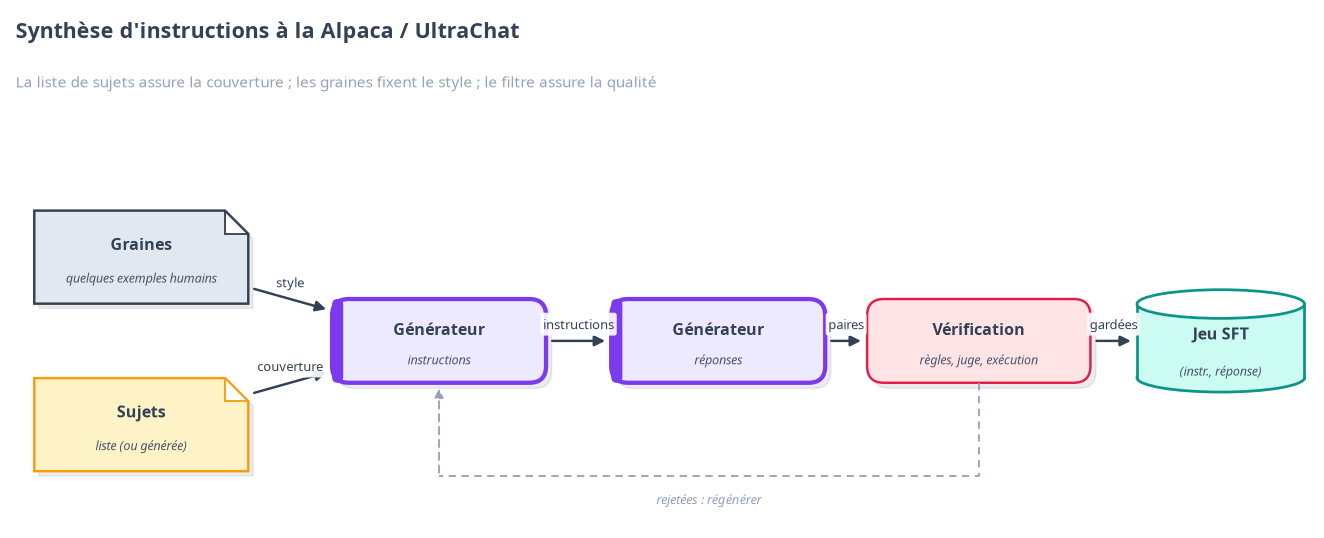

In [11]:
d = Diagram(14, 4.6, title="Synthèse d'instructions à la Alpaca / UltraChat",
            subtitle="La liste de sujets assure la couverture ; les graines fixent le style ; le filtre assure la qualité")
d.box("seed", 1.4, 2.9, "Graines", sub="quelques exemples humains", color=SLATE, kind="doc", w=2.3, h=1.0)
d.box("topics", 1.4, 1.1, "Sujets", sub="liste (ou générée)", color=AMBER, kind="doc", w=2.3, h=1.0)
d.box("g1", 4.6, 2.0, "Générateur", sub="instructions", color=VIOLET, kind="model", w=2.3)
d.box("g2", 7.6, 2.0, "Générateur", sub="réponses", color=VIOLET, kind="model", w=2.3)
d.box("filt", 10.4, 2.0, "Vérification", sub="règles, juge, exécution", color=ROSE, w=2.4)
d.box("ds", 13.0, 2.0, "Jeu SFT", sub="(instr., réponse)", color=TEAL, kind="db", w=1.8, h=1.1)
d.arrow("seed", "g1", "style")
d.arrow("topics", "g1", "couverture")
d.arrow("g1", "g2", "instructions")
d.arrow("g2", "filt", "paires")
d.arrow("filt", "ds", "gardées")
d.line([(10.4, 1.55), (10.4, 0.55), (4.6, 0.55), (4.6, 1.52)], color=GRAY, style="dashed")
d.note(7.5, 0.3, "rejetées : régénérer", color=GRAY, fontsize=8.5)
d.show()

### Générer des instructions par sujet

Mettons la recette en œuvre avec Qwen2.5-1.5B : six instructions graines (rédigées à la
main, cours 1) fixent le style, une liste de huit sujets assure la couverture, et l'on
demande trois instructions par sujet (température 0,8, graines aléatoires fixées).

In [12]:
graines = "\n".join(f"- {p[2]}" for p in d8.BASE_PAIRS[:6])


def prompt_instruction(sujet):
    return (f"Voici des exemples d'instructions qu'un utilisateur pourrait donner à un assistant :\n{graines}\n\n"
            f"Écris UNE nouvelle instruction, différente des exemples, sur le thème « {sujet} ». "
            "Réponds uniquement par l'instruction, en une phrase.")


def nettoie(t):
    return t.strip().strip('"«» ').split("\n")[0].strip()


sujets = ["jardinage", "impôts", "astronomie", "réparation de vélo", "histoire de France",
          "cuisine japonaise", "sécurité informatique", "éducation des enfants"]
synth = [{"sujet": s, "instruction": nettoie(llm.chat(prompt_instruction(s), GEN, max_new_tokens=50,
                                                      temperature=0.8, seed=k))}
         for s in sujets for k in range(3)]
synth = pd.DataFrame(synth)
synth.groupby("sujet").head(1).reset_index(drop=True)

,sujet,instruction
0,jardinage,Comment planifier un circuit d'été pour les amateurs de jardinage ?
1,impôts,Quelles sont les principales taxes et frais imposés en France et comment peuvent-ils être répartis entre r...
2,astronomie,Quelles sont les constellations notables d'été visible du Nord-Ouest?
3,réparation de vélo,Comment préparer de bonnes marques pour réparer son vélo sans trop dépenser ?
4,histoire de France,Quelles sont les dates importantes de la révolution française ?
5,cuisine japonaise,Quel est le processus exact de préparation du tempura au Japon ?
6,sécurité informatique,Comment prévenir les attaques maniables via phishing ?
7,éducation des enfants,Comment planifier les séances d'apprentissage efficaces pour favoriser la compréhension des enfants en bas...


Les instructions sont en général plausibles et bien ancrées dans leur sujet, avec des
maladresses (tournures étranges, fautes d'accord occasionnelles) : un modèle de 1,5
milliard de paramètres n'est pas un rédacteur professionnel. Générons maintenant une
réponse pour trois d'entre elles (décodage glouton, réponses tronquées à l'affichage).

In [13]:
trois = synth.iloc[[0, 9, 18]].copy()
trois["réponse (tronquée)"] = [court(llm.chat(i, GEN, max_new_tokens=90), 160) for i in trois.instruction]
trois[["instruction", "réponse (tronquée)"]]

,instruction,réponse (tronquée)
0,Comment planifier un circuit d'été pour les amateurs de jardinage ?,"Pour planifier un circuit d'été spécialisés dans le jardinage, voici quelques idées : 1. Visite à la ferme..."
9,Comment préparer de bonnes marques pour réparer son vélo sans trop dépenser ?,"Pour réparer un vélo sans dépenser beaucoup d'argent, voici quelques conseils : 1. Utilisez des pièces de ..."
18,Comment prévenir les attaques maniables via phishing ?,Prendre des mesures pour prévenir les attaques maniables par phishing nécessite une combinaison de techniq...


### Température et diversité

Faut-il échantillonner à haute température pour obtenir de la diversité ? Générons dix
instructions sur le même sujet (« jardinage ») à plusieurs températures et mesurons le
nombre d'instructions **uniques** et le score de Vendi (nombre effectif d'instructions
distinctes, cours 1).

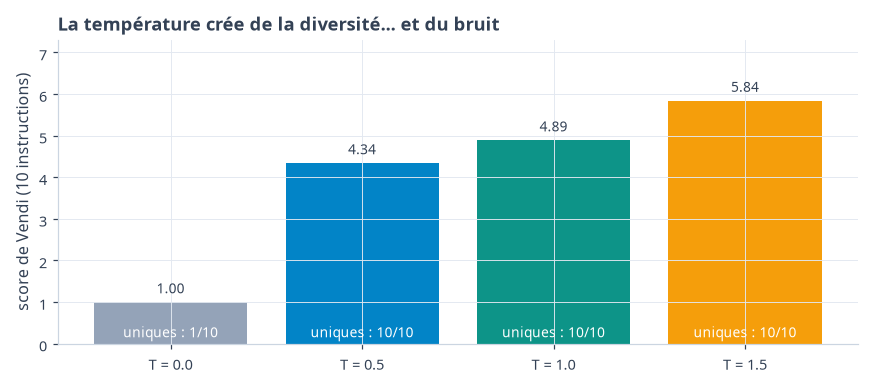

,T = 0.0,T = 1.5
0,Comment planifier une jardinière saisonnière pour maximiser la prod...,Comment planifier mes propres jardins d'hiver avec succès ? Dites-m...
1,Comment planifier une jardinière saisonnière pour maximiser la prod...,Quelles techniques utiliserez-vous pour planter ceinture d'oliviers...
2,Comment planifier une jardinière saisonnière pour maximiser la prod...,Comment améliorer l'humidité du terreau avant la planter les bulbes...


In [14]:
temps = [0.0, 0.5, 1.0, 1.5]
gen_t = {T: [nettoie(llm.chat(prompt_instruction("jardinage"), GEN, max_new_tokens=50, temperature=T, seed=s))
             for s in range(10)] for T in temps}
stats_t = pd.DataFrame({
    "température": temps,
    "uniques (sur 10)": [len(set(gen_t[T])) for T in temps],
    "Vendi": [d8.vendi_score(llm.embed(gen_t[T], llm.EMBED_MULTI)) for T in temps],
})
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar([f"T = {T}" for T in temps], stats_t["Vendi"], color=[GRAY, SKY, TEAL, AMBER])
annotate_bars(ax, "{:.2f}")
for i, u in enumerate(stats_t["uniques (sur 10)"]):
    ax.text(i, 0.15, f"uniques : {u}/10", ha="center", color="white", fontsize=9)
ax.set_ylabel("score de Vendi (10 instructions)")
ax.set_ylim(0, stats_t["Vendi"].max() * 1.25)
ax.set_title("La température crée de la diversité... et du bruit")
finish(fig)
plt.show()
pd.DataFrame({f"T = {T}": [court(t, 70) for t in gen_t[T][:3]] for T in [0.0, 1.5]})

À $T = 0$, le décodage est déterministe : dix fois la même instruction (Vendi = 1). La
diversité augmente avec la température, mais à $T = 1{,}5$ la qualité se dégrade
(vocabulaire incongru, phrases bancales) : la diversité gagnée l'est en partie sur du
**bruit**. Pour diversifier sans dégrader, le levier le plus sûr reste de varier le
**contenu du prompt** (sujets, sous-sujets, graines, formats de sortie) plutôt que la
température : c'est la logique d'UltraChat.

### Paraphrase et instruction inverse

Deux autres usages du livre : la **paraphrase** pour augmenter un jeu existant (MetaMath
a ainsi réécrit 15 000 problèmes en près de 400 000), et l'**instruction inverse**.

In [15]:
para = llm.chat("Donne trois reformulations différentes de la question « Comment réinitialiser mon mot de passe ? ». "
                "Une par ligne, sans numérotation ni commentaire.", GEN, max_new_tokens=80)
print("Paraphrases :")
for l in [l.strip("-0123456789. ") for l in para.split("\n") if l.strip()][:3]:
    print("  -", l)

inv = []
for lang, sujet, instr, rep in [d8.BASE_PAIRS[i] for i in (1, 9, 14, 17)]:
    q = llm.chat(f"Voici une réponse rédigée par un expert :\n« {rep} »\n"
                 "Quelle question un utilisateur a-t-il posée pour obtenir cette réponse ? "
                 "Réponds uniquement par la question.", GEN, max_new_tokens=40)
    inv.append({"réponse humaine (tronquée)": court(rep, 60), "instruction générée": nettoie(q),
                "instruction d'origine": instr})
inv = pd.DataFrame(inv)
E1 = llm.embed(inv["instruction générée"].tolist(), llm.EMBED_MULTI)
E2 = llm.embed(inv["instruction d'origine"].tolist(), llm.EMBED_MULTI)
inv["similarité cosinus"] = (E1 * E2).sum(1).round(2)
inv

Paraphrases :
  - Quels sont les étapes pour restaurer le compte après une perte du mot de passe ?
  - Comment procéder pour récupérer l'identifiant d'utilisateur et le mot de passe manquants ?
  - Que faut-il faire pour recharger son compte après avoir oublié sa clé de connexion ?


,réponse humaine (tronquée),instruction générée,instruction d'origine,similarité cosinus
0,"La béchamel se fait avec un roux et du lait, le velouté a...",Comment est-elle possible de préparer des sauces comme la béchamel et le velouté ?,Quelle est la différence entre une béchamel et un velouté ?,0.22
1,Les intérêts sont ajoutés au capital à chaque période et ...,Comment fonctionnent les intérêts simples et les intérêts compus dans un système financier ?,Qu'est-ce qu'un taux d'intérêt composé ?,0.51
2,Les saisons viennent de l'inclinaison de l'axe de la Terr...,Comment les saisons sont-elles causées par le mouvement de l'axe de rotation de la Terre?,Résume la cause principale des saisons sur Terre.,0.76
3,"Après les dernières gelées, en général de mi-avril à mi-m...",Quand est-ce que les gelées généralement se produisent et comment peuvent-elles être prédites ?,Quand faut-il planter des tomates ?,0.20


Les paraphrases sont utilisables mais dérivent parfois du sens d'origine (un
« identifiant » ou une « clé de connexion » apparaissent alors que la question ne portait
que sur le mot de passe) : une paraphrase doit elle aussi être vérifiée, par exemple par
similarité d'embeddings avec l'original.

Les instructions reconstituées sont plausibles, mais la similarité avec l'instruction
d'origine varie beaucoup : le modèle se concentre parfois sur un détail de la réponse
(pour la réponse sur les tomates, il interroge sur les gelées) ou pose une question plus
large que l'originale. Ce n'est pas rédhibitoire : l'important n'est pas de retrouver
l'instruction d'origine mais d'obtenir une instruction **à laquelle la réponse répond
bien**, ce qu'il faut vérifier (un juge peut noter l'adéquation question-réponse).
L'atout de la méthode demeure : la **réponse est fiable**, car écrite par un humain. Le livre décrit une boucle d'**auto-amélioration** fondée sur ce principe :
un modèle faible génère des instructions pour des textes de qualité, est affiné dessus,
puis recommence.

Autres recettes notables du livre : générer des paires question-réponse sur des
**morceaux** de documents longs puis poser la question avec le **document entier** en
contexte, pour apprendre à exploiter un contexte long ; et le pipeline de code de
Llama 3, que nous détaillons à la section suivante.

> **À retenir.** Un LLM peut générer instructions, réponses, ou les deux. La couverture
> vient de la liste de sujets et des graines, pas de la température, qui ajoute autant de
> bruit que de diversité. L'instruction inverse garde des réponses humaines et ne
> synthétise que la question.

## 6. Vérifier les données synthétiques (section *Data verification*)

Toute donnée synthétique doit être vérifiée, avec les mêmes outils que l'évaluation
(chapitres 3 et 4) : **correction fonctionnelle** quand c'est possible, **juges IA**
sinon, et **heuristiques**. Le livre observe qu'on synthétise surtout ce que l'on sait
vérifier : c'est pourquoi le code domine les données synthétiques de Llama 3, dont le
pipeline est un modèle du genre.

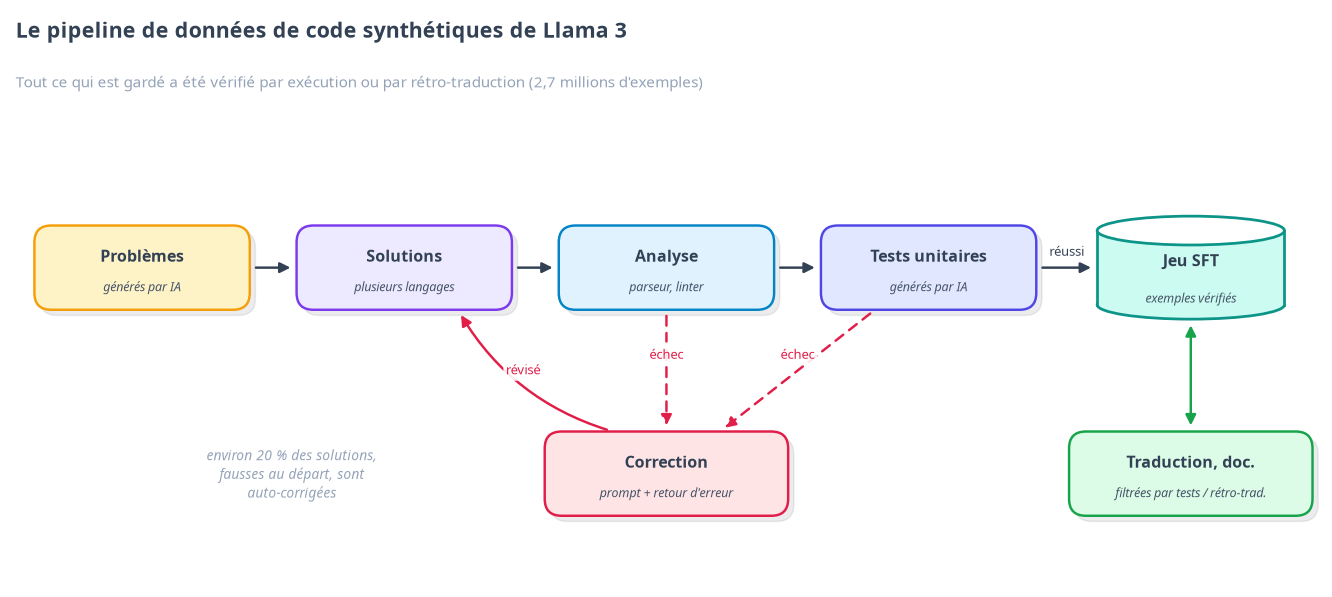

In [16]:
d = Diagram(14, 5.2, title="Le pipeline de données de code synthétiques de Llama 3",
            subtitle="Tout ce qui est gardé a été vérifié par exécution ou par rétro-traduction (2,7 millions d'exemples)")
d.flow([("pb", "Problèmes", "générés par IA"), ("sol", "Solutions", "plusieurs langages"),
        ("lint", "Analyse", "parseur, linter"), ("test", "Tests unitaires", "générés par IA")],
       y=3.4, x0=1.4, dx=2.8, w=2.3, colors=[AMBER, VIOLET, SKY, INDIGO])
d.box("fix", 7.0, 1.2, "Correction", sub="prompt + retour d'erreur", color=ROSE, w=2.6)
d.box("ok", 12.6, 3.4, "Jeu SFT", sub="exemples vérifiés", color=TEAL, kind="db", w=2.0, h=1.1)
d.box("trad", 12.6, 1.2, "Traduction, doc.", sub="filtrées par tests / rétro-trad.", color=GREEN, w=2.6)
d.arrow("test", "ok", "réussi")
d.arrow("lint", "fix", "échec", color=ROSE, style="dashed")
d.arrow("test", "fix", "échec", color=ROSE, style="dashed")
d.arrow("fix", "sol", "révisé", color=ROSE, rad=-0.2)
d.arrow("ok", "trad", both=True, color=GREEN)
d.note(3.0, 1.2, "environ 20 % des solutions,\nfausses au départ, sont\nauto-corrigées", color=GRAY)
d.show()

### 6.1 Correction fonctionnelle : des problèmes dont on connaît la réponse

Nos problèmes arithmétiques générés par gabarit ont une réponse exacte. Demandons à
Qwen2.5-0.5B (le « solveur ») de les résoudre avec un raisonnement pas à pas : on obtient
des paires (problème, raisonnement) **candidates** pour un jeu CoT, que l'on filtre en
comparant le nombre final à la vérité. On libère d'abord le générateur 1,5B de la mémoire.

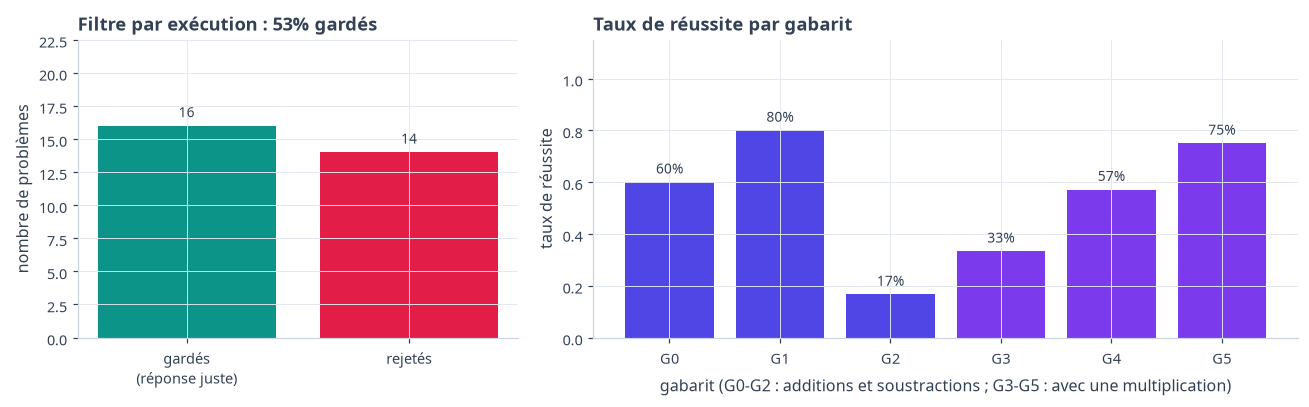

Exemple rejeté : Léa possède 55 billes. Elle en donne 12 à son frère et en gagne 8 à la récréation. Combien de billes a-t-elle ?
  sortie du solveur (fin) : bre total de billes que Léa a maintenant, nous devons ajouter ces deux montants : 55 (billes initiales) + 12 (billes données) + 8 (billes gagnées) = 75 Donc, Léa a 75 billes en total. Résultat : 75
  attendu : 51


In [17]:
llm.free_gpu()
pbs = d8.make_word_problems(30, seed=0)
sorties = [llm.chat(p["question"] + " Raisonne étape par étape puis termine par « Réponse : <nombre> ».",
                    SOLV, max_new_tokens=220) for p in pbs]
verif = pd.DataFrame({"gabarit": [p["template"] for p in pbs], "attendu": [p["answer"] for p in pbs],
                      "obtenu": [d8.extract_number(s) for s in sorties]})
verif["correct"] = verif.attendu == verif.obtenu
taux_ok = verif.correct.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.bar(["gardés\n(réponse juste)", "rejetés"], [verif.correct.sum(), (~verif.correct).sum()], color=[TEAL, ROSE])
annotate_bars(ax, "{:.0f}")
ax.set_ylim(0, len(verif) * 0.75)
ax.set_ylabel("nombre de problèmes")
ax.set_title(f"Filtre par exécution : {taux_ok:.0%} gardés")
ax = axes[1]
g = verif.groupby("gabarit").correct.mean()
ax.bar([f"G{k}" for k in g.index], g.values, color=[INDIGO if k < 3 else VIOLET for k in g.index])
annotate_bars(ax, "{:.0%}")
ax.set_ylim(0, 1.15)
ax.set_xlabel("gabarit (G0-G2 : additions et soustractions ; G3-G5 : avec une multiplication)")
ax.set_ylabel("taux de réussite")
ax.set_title("Taux de réussite par gabarit")
finish(fig)
plt.show()
i_bad = int(np.flatnonzero(~verif.correct.values)[0])
print("Exemple rejeté :", court(pbs[i_bad]["question"], 140))
print("  sortie du solveur (fin) :", court(sorties[i_bad][-200:], 200))
print("  attendu :", pbs[i_bad]["answer"])

Le petit modèle échoue sur une part importante des problèmes (erreurs de calcul,
raisonnements tronqués ou mal conclus) : sans vérification, ces raisonnements faux
entreraient dans le jeu d'entraînement et enseigneraient des erreurs. Le filtre ne garde
que les exemples justes, et la répartition par gabarit indique **où** le modèle est
faible : les taux varient fortement d'un gabarit à l'autre (avec seulement cinq
problèmes par gabarit, ces taux restent toutefois très incertains). Deux mises en garde :

- une réponse finale juste n'implique pas un raisonnement juste (le modèle a pu se
  tromper deux fois) : la vérification par le résultat est **nécessaire, pas
  suffisante** ;
- filtrer **biaise** le jeu vers les problèmes faciles : il faut surveiller la
  couverture après filtrage (ici, les gabarits difficiles seraient sous-représentés).

### 6.2 Heuristiques et juge IA sur les instructions synthétiques

Pour des données non vérifiables par exécution, le livre propose des **heuristiques**
(celles de Self-Instruct : instructions trop courtes ou trop longues, réponses vides ou
qui répètent l'instruction, instructions quasi dupliquées) et des **vérificateurs IA** :
un juge qui note chaque exemple, un classifieur de sujet qui écarte les hors-sujet, un
détecteur d'anomalies. Appliquons les heuristiques à nos 24 instructions générées, puis
un contrôle de **pertinence thématique** par embeddings : chaque instruction doit être
plus proche de son sujet que des autres sujets.

In [18]:
gardees, raisons = [], []
for ins in synth.instruction:
    ok, raison = d8.self_instruct_filter(ins, "(réponse à générer)", gardees, rouge_max=0.7)
    raisons.append(raison)
    if ok:
        gardees.append(ins)
synth["filtre heuristique"] = raisons
Es = llm.embed(synth.instruction.tolist(), llm.EMBED_MULTI)
Et = llm.embed([f"une question sur le thème : {s}" for s in sujets], llm.EMBED_MULTI)
pred = np.array(sujets)[(Es @ Et.T).argmax(1)]
synth["sujet détecté"] = pred
synth["pertinent"] = synth["sujet détecté"] == synth["sujet"]
print(synth["filtre heuristique"].value_counts().to_string())
print(f"Instructions jugées dans leur sujet : {synth.pertinent.mean():.0%}")
synth.loc[~synth.pertinent | (synth["filtre heuristique"] != "ok"), ["sujet", "instruction", "filtre heuristique", "sujet détecté"]].head(6)

filtre heuristique
ok                             23
instruction quasi dupliquée     1
Instructions jugées dans leur sujet : 100%


,sujet,instruction,filtre heuristique,sujet détecté
13,histoire de France,Quelles sont les principales villes historiques de la Révolution française ?,instruction quasi dupliquée,histoire de France


Sur cet échantillon, les heuristiques écartent peu d'instructions (des quasi-doublons
produits pour un même sujet) et le contrôle thématique en accepte la quasi-totalité : le
générateur 1,5B suit bien la consigne de sujet. Mais ces deux filtres sont aveugles à la
**qualité linguistique et factuelle** : une instruction maladroite comme « prévenir les
attaques maniables via phishing » passe les deux. Il faut donc compléter par un juge (IA
ou humain) et une inspection manuelle d'un échantillon ; l'exercice 8.8 construit un juge
IA et mesure son biais de position. Inversement, quand un vérificateur automatique
signale un exemple, on inspecte avant de supprimer : il a aussi ses erreurs.

### 6.3 Rétro-traduction

Pour des traductions (par exemple vers une langue peu dotée), le livre propose la
**rétro-traduction** : traduire $X$ en $Y$, retraduire $Y$ en $X'$, et comparer $X'$ à
$X$. Si elles divergent, la traduction $Y$ est suspecte. On traduit six phrases en
anglais, on **corrompt volontairement** deux traductions (l'une est remplacée par la
traduction d'une autre phrase, l'autre est tronquée), puis on retraduit tout.

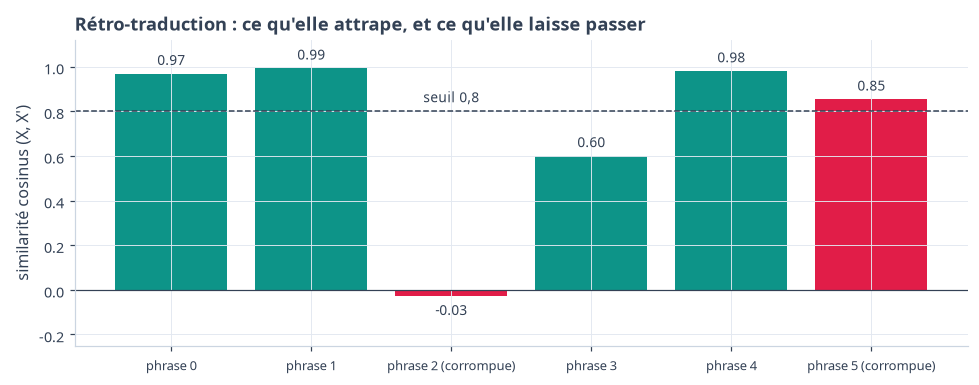

,X (original),Y (anglais),X' (retour),sim.
0,Entre sept et neuf heures par nuit pour la plupart d...,Between seven and nine o'clock at night for most adu...,Entre sept et neuf heures du soir pour la plupart de...,0.97
1,"Elle améliore la santé cardiovasculaire, aide à cont...","She improves cardiovascular health, helps control we...","Elle améliore la santé cardiaque, contrôle le poids,...",0.99
2,Les intérêts sont ajoutés au capital à chaque périod...,A valid passport for the entire duration of stay; ge...,Un passeport valide pour toute la durée de séjour ; ...,-0.03
3,"Listez vos revenus, retirez les dépenses fixes (loye...",Here's the English translation without any commentar...,"Voici la traduction en français, sans commentaires :...",0.60
4,Un passeport valide pour toute la durée du séjour ; ...,A valid passport for the entire duration of stay; ge...,Un passeport valide pour toute la durée de séjour ; ...,0.98
5,"Adaptez vos horaires de sommeil avant le départ, exp...",Adjust your sleep schedule before,Avancez votre horaire de sommeil avant,0.85


In [19]:
llm.free_gpu()  # on décharge le solveur 0,5B avant de recharger le générateur
srcs = [p[3] for p in d8.BASE_PAIRS[7:13]]
fr2en = lambda t: llm.chat(f"Traduis en anglais, sans commentaire :\n{t}", GEN, max_new_tokens=80)
en2fr = lambda t: llm.chat(f"Traduis en français, sans commentaire :\n{t}", GEN, max_new_tokens=80)
trads = [fr2en(t) for t in srcs]
trads[2] = trads[4]                       # corruption 1 : mauvaise phrase
trads[5] = " ".join(trads[5].split()[:5])  # corruption 2 : traduction tronquée
retour = [en2fr(t) for t in trads]
sim = (llm.embed(srcs, llm.EMBED_MULTI) * llm.embed(retour, llm.EMBED_MULTI)).sum(1)
llm.free_gpu()

fig, ax = plt.subplots(figsize=(9, 3.6))
cols = [ROSE if i in (2, 5) else TEAL for i in range(6)]
ax.bar([f"phrase {i}" + (" (corrompue)" if i in (2, 5) else "") for i in range(6)], sim, color=cols)
annotate_bars(ax, "{:.2f}")
ax.axhline(0.8, color=SLATE, ls="--", lw=1)
ax.text(2, 0.84, "seuil 0,8", ha="center", fontsize=9)
ax.set_ylim(min(-0.25, sim.min() - 0.1), 1.12)
ax.axhline(0, color=SLATE, lw=0.8)
ax.set_ylabel("similarité cosinus (X, X')")
ax.set_title("Rétro-traduction : ce qu'elle attrape, et ce qu'elle laisse passer")
plt.setp(ax.get_xticklabels(), fontsize=8.5)
finish(fig)
plt.show()
pd.DataFrame({"X (original)": [court(t, 55) for t in srcs], "Y (anglais)": [court(t, 55) for t in trads],
              "X' (retour)": [court(t, 55) for t in retour], "sim.": sim.round(2)})

Lisez le tableau ligne par ligne, le bilan est instructif :

- la traduction **remplacée** par celle d'une autre phrase est démasquée sans peine
  (similarité proche de zéro) ;
- la traduction **tronquée** passe le seuil : son retour ne contient que le début de la
  phrase, mais ce début suffit à rendre les embeddings proches. Une similarité globale
  est indulgente avec les omissions ;
- une traduction **correcte sur le fond** est signalée parce que le modèle a ajouté un
  préambule (« Here's the English translation... ») : la rétro-traduction attrape ici une
  pollution de **format**, qu'il faudrait de toute façon nettoyer (cours 3) ;
- plus subtil, regardez la phrase 0 : « entre sept et neuf heures par nuit » est devenu
  « between seven and nine o'clock at night » (de 19 h à 21 h !), et le retour en
  français reproduit fidèlement le contresens. Une erreur **symétrique** survit à
  l'aller-retour : la rétro-traduction ne garantit pas le sens.

Comme tout vérificateur automatique, la rétro-traduction a des faux négatifs et des faux
positifs ; elle trie un grand volume, et l'humain inspecte ce qui reste douteux. Llama 3
applique la même idée au code : une explication générée n'est gardée que si le code
régénéré **à partir de l'explication** reste fidèle au code d'origine (et là, des tests
unitaires rendent la comparaison bien plus stricte qu'une similarité d'embeddings).

> **À retenir.** On synthétise d'abord ce que l'on sait vérifier. Correction
> fonctionnelle (exécution, réponse connue), rétro-traduction, juges et classifieurs,
> heuristiques à la Self-Instruct : chaque filtre a ses angles morts, et filtrer peut
> biaiser la couverture. Le test ultime reste l'effet sur le modèle entraîné.

## 7. Limites des données générées et effondrement de modèle (section *Limitations to AI-generated data*)

Le livre retient quatre limites :

1. **le contrôle qualité** : « garbage in, garbage out », et l'on hésite à utiliser ce
   que l'on ne sait pas évaluer ;
2. **l'imitation superficielle** : un élève qui imite un professeur copie son **style**
   mais pas forcément ses connaissances ; pire, entraîner un modèle sur des solutions
   qu'il est incapable de trouver lui apprend à **produire des choses qui ressemblent à
   des solutions**, c'est-à-dire à halluciner ;
3. **l'effondrement de modèle** (« model collapse ») : entraîné récursivement sur ses
   propres sorties, un modèle perd progressivement les événements rares ;
4. **la lignée opaque** : si le modèle générateur a été entraîné sur des données sous
   droits ou sur votre benchmark, votre modèle hérite du problème (violation de droits,
   contamination) sans que vous le sachiez.

### Une gaussienne qui s'effondre

Le mécanisme se démontre sur le modèle le plus simple. À chaque génération $t$, on
tire $n$ échantillons du modèle courant $\mathcal N(\mu_t, \sigma_t^2)$ et l'on réestime
$\mu_{t+1}, \sigma_{t+1}$ par maximum de vraisemblance. L'estimateur de la variance est
biaisé : $\mathbb E[\hat\sigma^2] = \frac{n-1}{n}\sigma^2$. Par récurrence,
$$\mathbb E[\sigma_t^2] = \sigma_0^2\left(\frac{n-1}{n}\right)^t \xrightarrow[t\to\infty]{} 0.$$
Plus encore, $\log \sigma_t^2$ suit une marche aléatoire à dérive négative : la plupart
des trajectoires s'effondrent bien plus vite que la moyenne ne le laisse croire. La
distribution se contracte vers un point : **les queues disparaissent en premier**.

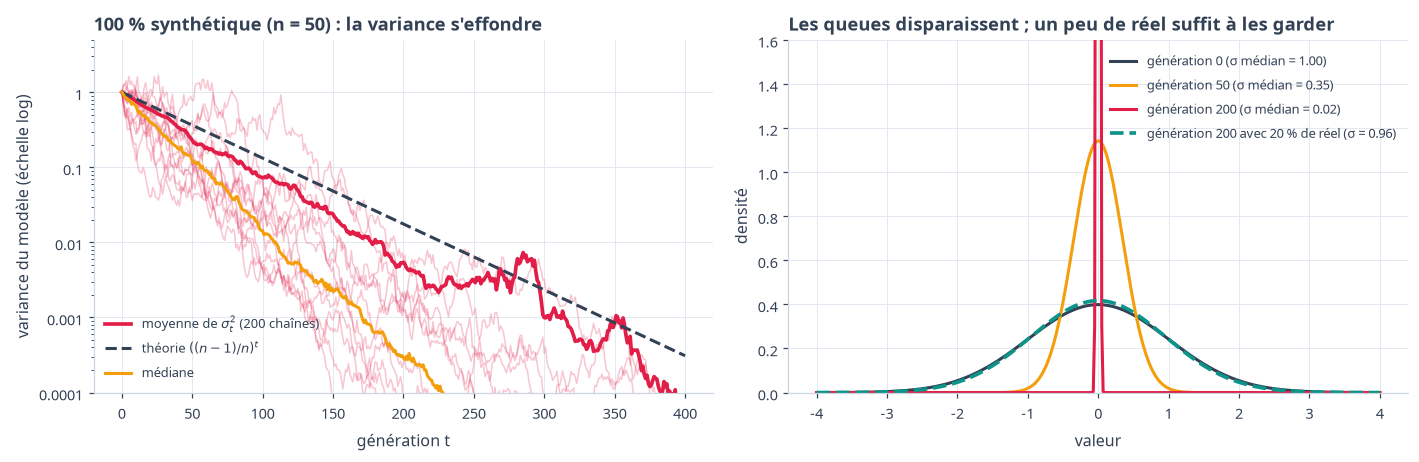

In [20]:
n_ech, T_gen, runs = 50, 400, 200
traj = np.array([d8.gaussian_collapse(n_ech, T_gen, 0.0, seed=r)[1] for r in range(runs)])
traj_mix = np.array([d8.gaussian_collapse(n_ech, T_gen, 0.2, seed=r)[1] for r in range(runs)])
t = np.arange(T_gen + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for r in range(12):
    ax.plot(t, traj[r] ** 2, color=ROSE, alpha=0.25, lw=1)
ax.plot(t, (traj ** 2).mean(0), color=ROSE, lw=2.4, label="moyenne de $\\sigma_t^2$ (200 chaînes)")
ax.plot(t, ((n_ech - 1) / n_ech) ** t, color=SLATE, ls="--", label="théorie $((n-1)/n)^t$")
ax.plot(t, np.median(traj ** 2, 0), color=AMBER, lw=2, label="médiane")
ax.set_yscale("log")
ax.set_ylim(1e-4, 5)
log_lisible(ax)
ax.set_xlabel("génération t")
ax.set_ylabel("variance du modèle (échelle log)")
ax.set_title(f"100 % synthétique (n = {n_ech}) : la variance s'effondre")
ax.legend(loc="lower left", fontsize=8.5)
ax = axes[1]
xs = np.linspace(-4, 4, 400)
for gen, c in [(0, SLATE), (50, AMBER), (200, ROSE)]:
    sg = np.median(traj[:, gen])
    ax.plot(xs, np.exp(-xs ** 2 / (2 * sg ** 2)) / (sg * np.sqrt(2 * np.pi)), color=c,
            label=f"génération {gen} (σ médian = {sg:.2f})")
sgm = np.median(traj_mix[:, 200])
ax.plot(xs, np.exp(-xs ** 2 / (2 * sgm ** 2)) / (sgm * np.sqrt(2 * np.pi)), color=TEAL, ls="--", lw=2.4,
        label=f"génération 200 avec 20 % de réel (σ = {sgm:.2f})")
ax.set_ylim(0, 1.6)
ax.set_xlabel("valeur")
ax.set_ylabel("densité")
ax.set_title("Les queues disparaissent ; un peu de réel suffit à les garder")
ax.legend(loc="upper right", fontsize=8.5)
finish(fig)
plt.show()

### Des événements rares qui disparaissent

Le livre propose une explication intuitive : un modèle génère plus volontiers les
événements **probables** (ne pas avoir de cancer) que les **improbables** (en avoir un).
Simulons une distribution de Zipf sur 200 « événements » : à chaque génération, on
génère 2 000 exemples avec la distribution courante, puis on réestime les fréquences.
Un événement qui n'est tiré aucune fois a une fréquence estimée nulle et **ne reviendra
jamais**. On compare un décodage fidèle ($T = 1$), un décodage qui favorise les
événements probables ($T = 0{,}9$, comme beaucoup de décodages réels), et un mélange
avec 20 % de données réelles à chaque génération.

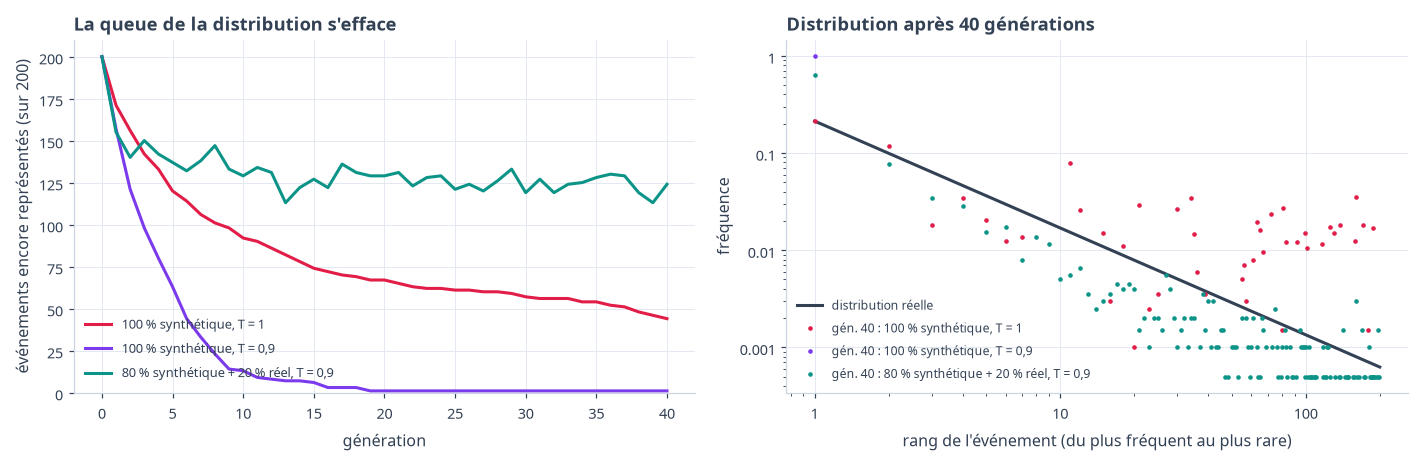

In [21]:
K_ev = 200
p0 = 1 / np.arange(1, K_ev + 1) ** 1.1
p0 /= p0.sum()
scen = {"100 % synthétique, T = 1": dict(temperature=1.0, real_frac=0.0, c=ROSE),
        "100 % synthétique, T = 0,9": dict(temperature=0.9, real_frac=0.0, c=VIOLET),
        "80 % synthétique + 20 % réel, T = 0,9": dict(temperature=0.9, real_frac=0.2, c=TEAL)}
H = {k: d8.categorical_collapse(p0, 2000, 40, real_frac=v["real_frac"], temperature=v["temperature"], seed=0)
     for k, v in scen.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for k, v in scen.items():
    ax.plot((H[k] > 0).sum(1), color=v["c"], label=k)
ax.set_xlabel("génération")
ax.set_ylabel("événements encore représentés (sur 200)")
ax.set_ylim(0, 210)
ax.set_title("La queue de la distribution s'efface")
ax.legend(loc="lower left", fontsize=8.5)
ax = axes[1]
rangs = np.arange(1, K_ev + 1)
ax.plot(rangs, p0, color=SLATE, lw=2, label="distribution réelle")
for k, v in scen.items():
    h = H[k][-1]
    ax.plot(rangs[h > 0], h[h > 0], ".", color=v["c"], ms=4, label=f"gén. 40 : {k}")
ax.set_xscale("log"); ax.set_yscale("log")
log_lisible(ax, "xy")
ax.set_xlabel("rang de l'événement (du plus fréquent au plus rare)")
ax.set_ylabel("fréquence")
ax.set_title("Distribution après 40 générations")
ax.legend(loc="lower left", fontsize=8)
finish(fig)
plt.show()

Même avec un décodage parfaitement fidèle, les événements rares disparaissent un à un
(le hasard de l'échantillonnage suffit) ; un décodage qui favorise les événements
probables accélère l'effondrement et **amplifie** les événements fréquents, ce que le
livre relie aux boucles de rétroaction qui amplifient les biais (*Data Feedback Loops*).
L'injection de données réelles à chaque génération empêche la queue de mourir : c'est la
conclusion des travaux cités (*Is Model Collapse Inevitable?*), qui ne donnent toutefois
pas de proportion universelle. À l'inverse, Nemotron-4 340B a utilisé 98 % de données
synthétiques en post-entraînement avec succès, mais sur **une seule** génération.

> **À retenir.** Entraîner récursivement sur des données générées contracte la
> distribution : les événements rares disparaissent d'abord, les fréquents sont
> amplifiés. Mélanger des données réelles à chaque génération l'évite. S'y ajoutent
> l'imitation superficielle (copier le style sans la compétence) et la lignée opaque
> (droits d'auteur, contamination des benchmarks).

## 8. Distillation de modèles (section *Model Distillation*)

La **distillation** (Hinton et al., 2015) entraîne un petit modèle **élève** à imiter un
grand modèle **professeur**. Exemples du livre : DistilBERT (40 % plus petit, 97 % des
capacités de compréhension, 60 % plus rapide), Alpaca (Llama-7B affiné sur des sorties
de text-davinci-003, un modèle environ 25 fois plus gros). Attention : de nombreuses
licences **interdisent** d'utiliser les sorties d'un modèle pour en entraîner un autre.

**Pourquoi les sorties d'un professeur valent-elles mieux que des étiquettes ?** Une
étiquette dure dit « c'est un chat ». La distribution du professeur dit « chat à 90 %,
un peu lynx, pas du tout voiture » : elle encode des **similarités** entre classes. La
perte de distillation compare les distributions adoucies par une température $T$ :
$$\mathcal L_{KD} = T^2\, \mathrm{KL}\big(\mathrm{softmax}(z^{prof}/T)\,\big\|\,\mathrm{softmax}(z^{élève}/T)\big),$$
où le facteur $T^2$ compense la réduction des gradients quand $T$ grandit. Pour les LLM,
on dispose rarement des logits du professeur (API) : on distille alors sur ses **textes**
générés, ce qui revient aux étiquettes dures token par token.

### Ce que voit l'élève : la distribution du professeur

Comparons, pour quelques débuts de phrase, la distribution du prochain token de
Qwen2.5-1.5B (professeur) et de Qwen2.5-0.5B (élève potentiel). Les modèles sont chargés
l'un après l'autre.

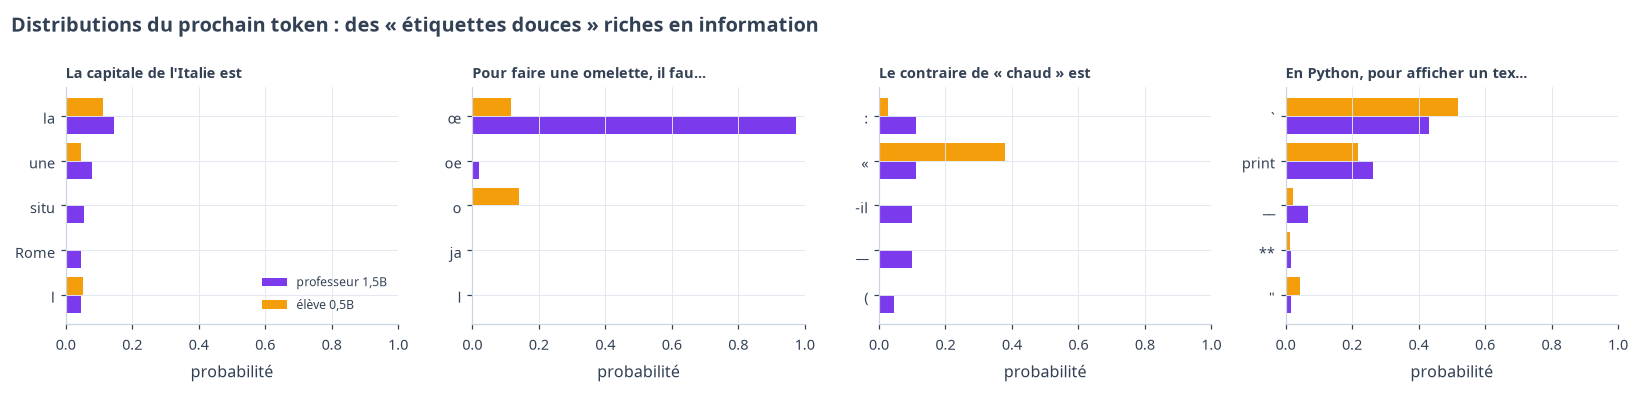

In [22]:
contextes = ["La capitale de l'Italie est", "Pour faire une omelette, il faut casser des",
             "Le contraire de « chaud » est", "En Python, pour afficher un texte, on utilise la fonction"]
dist = {}
for mid in (GEN, SOLV):
    dist[mid] = [llm.next_token_distribution(c, mid, k=6) for c in contextes]
    llm.free_gpu()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, c, dp, de in zip(axes, contextes, dist[GEN], dist[SOLV]):
    toks = [repr(t)[1:-1] for t in dp.tokens[:5]]
    pe = {t: p for t, p in zip(de.tokens, de.probs)}
    ys = np.arange(5)
    ax.barh(ys + 0.2, dp.probs[:5], 0.4, color=VIOLET, label="professeur 1,5B")
    ax.barh(ys - 0.2, [pe.get(t, 0) for t in dp.tokens[:5]], 0.4, color=AMBER, label="élève 0,5B")
    ax.set_yticks(ys, toks)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(court(c, 34), fontsize=9.5)
    ax.set_xlabel("probabilité")
axes[0].legend(loc="lower right", fontsize=8)
finish(fig, "Distributions du prochain token : des « étiquettes douces » riches en information")
plt.show()

Même quand le token le plus probable est évident, la distribution du professeur porte de
l'information sur les **alternatives** (variantes de casse, synonymes, tokens de début
de mot). Un élève entraîné sur ces distributions apprend plus par exemple qu'avec le seul
token choisi. (Les tokens absents du top 6 de l'élève apparaissent à probabilité nulle
sur la figure.)

### Expérience de distillation dans notre petit monde

Reprenons le problème synthétique du cours 1. Un **professeur** (réseau de 128 neurones
cachés) est entraîné sur 6 000 exemples étiquetés. L'**élève** (8 neurones cachés) ne
dispose que de **300** exemples étiquetés, mais de 5 000 exemples **non étiquetés** (un
« jeu de transfert ») que le professeur peut annoter. On compare :

1. l'élève entraîné sur ses 300 étiquettes ;
2. l'élève entraîné sur les **étiquettes dures** du professeur (son choix) ;
3. l'élève entraîné sur les **étiquettes douces** du professeur (ses probabilités, à
   $T = 1$ et $T = 2$) ;
4. pour référence, l'élève entraîné sur 6 000 vraies étiquettes.

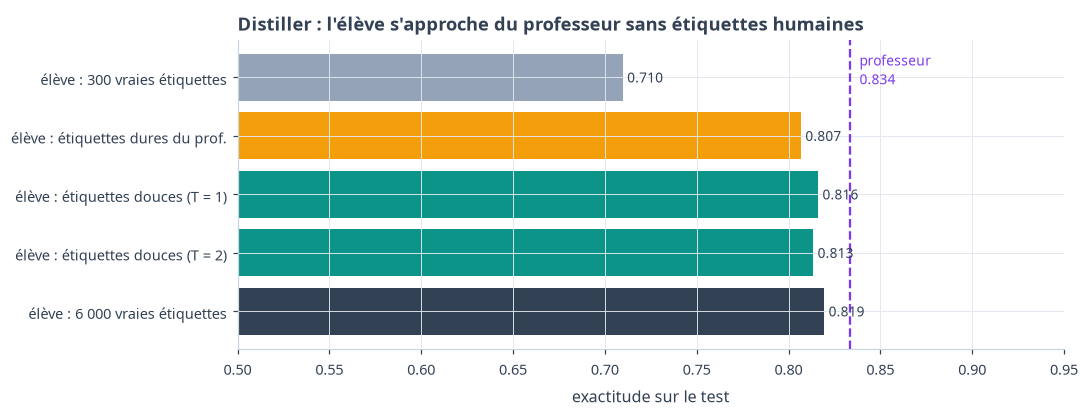

In [23]:
from aie.llm import softmax

X, y, s, centres = d8.make_subpop_data(6000, sep=1.0, seed=0)
U, _, _, _ = d8.make_subpop_data(5000, sep=1.0, seed=5, centers=centres)
Xt, yt, _, _ = d8.make_subpop_data(3000, sep=1.0, seed=1, centers=centres)
exact = lambda f: float(np.mean(f(Xt).argmax(1) == yt))

prof = d8.train_mlp(X, y, 4, hidden=128, epochs=60)
zU = prof.logits(U)
variantes = {
    "élève : 300 vraies étiquettes": d8.train_mlp(X[:300], y[:300], 4, hidden=8, epochs=300),
    "élève : étiquettes dures du prof.": d8.train_mlp(U, zU.argmax(1), 4, hidden=8, epochs=60),
    "élève : étiquettes douces (T = 1)": d8.train_mlp(U, softmax(zU, 1.0), 4, hidden=8, epochs=60),
    "élève : étiquettes douces (T = 2)": d8.train_mlp(U, softmax(zU, 2.0), 4, hidden=8, epochs=60),
    "élève : 6 000 vraies étiquettes": d8.train_mlp(X, y, 4, hidden=8, epochs=60),
}
scores = {k: exact(f) for k, f in variantes.items()}

fig, ax = plt.subplots(figsize=(10, 3.9))
cols = [GRAY, AMBER, TEAL, TEAL, SLATE]
ax.barh(list(scores), list(scores.values()), color=cols)
annotate_bars(ax, "{:.3f}")
ax.axvline(exact(prof), color=VIOLET, ls="--", lw=1.5)
ax.text(exact(prof) + 0.005, -0.45, f"professeur\n{exact(prof):.3f}", color=VIOLET, fontsize=9, va="top")
ax.invert_yaxis()
ax.set_xlim(0.5, 0.95)
ax.set_xlabel("exactitude sur le test")
ax.set_title("Distiller : l'élève s'approche du professeur sans étiquettes humaines")
finish(fig)
plt.show()

Les annotations du professeur sur des données non étiquetées permettent à l'élève de
dépasser largement ce qu'il obtient avec ses seules 300 étiquettes, et de s'approcher
de l'élève entraîné sur 6 000 vraies étiquettes : le professeur a joué le rôle d'un
**annotateur gratuit**. L'écart entre étiquettes douces et dures est faible ici (le
problème a peu de classes) ; il grandit avec le nombre de classes et leurs ressemblances.
Enfin, l'élève reste **plafonné** par sa propre capacité et par le professeur : on ne
distille pas une compétence que l'élève ne peut pas représenter.

**Toute synthèse n'est pas de la distillation.** La distillation suppose que le
professeur est l'étalon. Le livre cite des contre-exemples où l'élève **dépasse** son
générateur : Nemotron-4-340B-Instruct, affiné sur des données produites par
Mixtral-8x7B, plus petit ; ou l'auto-amélioration par instruction inverse. Llama 3
conclut qu'entraîner sans discernement un modèle sur ses propres sorties ne l'améliore
pas, mais qu'avec une **vérification** rigoureuse des données, on peut l'améliorer en
continu.

> **À retenir.** La distillation transfère la compétence d'un grand modèle vers un petit
> via les sorties du grand : étiquettes douces (logits) quand on y a accès, textes
> générés sinon. Elle transforme des données non étiquetées en données d'entraînement,
> dans la limite de la capacité de l'élève et des licences.

## Synthèse

- **Augmentation** (à partir du réel) et **synthèse** (imitation du réel) servent la
  quantité, la couverture, la qualité, la vie privée et la distillation.
- **Règles et gabarits** : peu coûteux, structurés, vérifiables ; diversité bornée par la
  combinatoire.
- **Perturbations et contrefactuels** : robustesse et atténuation des biais, si
  l'étiquette est préservée.
- **Simulation** : générer, exécuter, garder ce qui réussit ; indispensable pour les
  événements rares et l'usage d'outils.
- **Synthèse par IA** : sujets et graines pour la couverture, instruction inverse pour
  la fiabilité ; la température ajoute autant de bruit que de diversité.
- **Vérification** : exécution, rétro-traduction, juges, heuristiques ; on synthétise ce
  que l'on sait vérifier.
- **Limites** : effondrement de modèle (démontré sur une gaussienne et une loi de Zipf),
  imitation superficielle, lignée opaque ; mélanger du réel protège.
- **Distillation** : un professeur annote gratuitement, l'élève est plafonné par sa
  capacité.

**Liens.** Les juges IA et la détection d'incohérences factuelles viennent des
chapitres 3 et 4 ; les données produites ici alimentent l'affinage du chapitre 7. Le
**cours 3** traite ces données brutes : inspection, déduplication, nettoyage, mise au
format.

In [24]:
llm.free_gpu()